# DeepHealthX — Two-Stage Multi-Modal Heart Disease Detection

In [1]:
import sys, warnings, pickle
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

import nibabel as nib
import cv2

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", len(tf.config.list_physical_devices('GPU')) > 0)

# Suppress noisy TF retracing warnings
tf.get_logger().setLevel('ERROR')


TensorFlow: 2.13.0
GPU: False


In [2]:
DATA_DIR   = Path('../data')
MODELS_DIR = Path('../models')
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

CLINICAL_DATA      = DATA_DIR / 'heart.csv'
ECG_TRAIN          = DATA_DIR / 'mitbih_train.csv'
ECG_TEST           = DATA_DIR / 'mitbih_test.csv'
MRI_DIR            = DATA_DIR / 'training' / 'training'
CLINICAL_MODEL_PATH = MODELS_DIR / 'clinical_model.h5'
ECG_MODEL_PATH      = MODELS_DIR / 'ecg_model.h5'
MRI_MODEL_PATH      = MODELS_DIR / 'mri_model.h5'
FUSION_MODEL_PATH   = MODELS_DIR / 'fusion_model.h5'

CONFIG = {
    'clinical_embedding_dim': 32,
    'ecg_embedding_dim': 64,
    'mri_embedding_dim': 64,
    'mri_image_size': (224, 224),
    'ecg_signal_length': 187,
    'batch_size': 32,
    'epochs': 30,
    'validation_split': 0.2,
    'random_seed': 42
}


## 1. Clinical Data

In [3]:
df = pd.read_csv(CLINICAL_DATA)
df = df.fillna(df.mean())

X = df.drop('target', axis=1) if 'target' in df.columns else df.iloc[:, :-1]
y = df['target']              if 'target' in df.columns else df.iloc[:, -1]

clinical_scaler = MinMaxScaler()
X_scaled = clinical_scaler.fit_transform(X)

X_clinical_train, X_clinical_test, y_clinical_train, y_clinical_test = train_test_split(
    X_scaled, y.values,
    test_size=CONFIG['validation_split'],
    random_state=CONFIG['random_seed'],
    stratify=y
)

with open(str(MODELS_DIR / 'clinical_scaler.pkl'), 'wb') as f:
    pickle.dump(clinical_scaler, f)

print(f"Clinical — train: {X_clinical_train.shape}  test: {X_clinical_test.shape}")
print(f"Label distribution: {dict(zip(*np.unique(y_clinical_train, return_counts=True)))}")


Clinical — train: (242, 13)  test: (61, 13)
Label distribution: {0: 110, 1: 132}


## 2. ECG Data

In [4]:
ecg_train_df = pd.read_csv(ECG_TRAIN, header=None)
ecg_test_df  = pd.read_csv(ECG_TEST,  header=None)

X_ecg_train = ecg_train_df.iloc[:, :-1].values.astype(np.float32)
y_ecg_train = ecg_train_df.iloc[:, -1].values
X_ecg_test  = ecg_test_df.iloc[:, :-1].values.astype(np.float32)
y_ecg_test  = ecg_test_df.iloc[:, -1].values

ecg_scaler  = StandardScaler()
X_ecg_train = ecg_scaler.fit_transform(X_ecg_train).reshape(-1, 187, 1)
X_ecg_test  = ecg_scaler.transform(X_ecg_test).reshape(-1, 187, 1)

y_ecg_train_binary = (y_ecg_train > 0).astype(int)
y_ecg_test_binary  = (y_ecg_test  > 0).astype(int)

print(f"ECG — train: {X_ecg_train.shape}  test: {X_ecg_test.shape}")
print(f"Normal: {(y_ecg_train_binary==0).sum()}  Arrhythmia: {(y_ecg_train_binary==1).sum()}")


ECG — train: (87554, 187, 1)  test: (21892, 187, 1)
Normal: 72471  Arrhythmia: 15083


## 3. MRI Data

In [5]:
def extract_label_from_info(cfg_path):
    with open(cfg_path, 'r') as f:
        for line in f:
            if 'Group' in line:
                group = line.split(':')[1].strip()
                return 0 if group == 'NOR' else 1
    return None

def load_and_preprocess_mri_data():
    images, labels = [], []
    patient_folders = [p for p in MRI_DIR.iterdir() if p.is_dir()]

    for patient in patient_folders:
        cfg_file = patient / 'Info.cfg'
        if not cfg_file.exists():
            continue
        label = extract_label_from_info(cfg_file)
        if label is None:
            continue
        for file in patient.glob('*frame*.nii.gz'):
            if '_gt' in file.name:
                continue
            try:
                data = nib.load(str(file)).get_fdata()
                for idx in [data.shape[2]//4, data.shape[2]//2, (3*data.shape[2])//4]:
                    slc = data[:, :, idx].astype(np.float32)
                    slc = (slc - slc.min()) / (slc.max() - slc.min() + 1e-8)
                    slc = cv2.resize(slc, (224, 224))
                    images.append(np.stack([slc]*3, axis=-1))
                    labels.append(label)
            except Exception:
                pass

    X = np.array(images, dtype=np.float32)
    y = np.array(labels)
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_mri_train, X_mri_test, y_mri_train, y_mri_test = load_and_preprocess_mri_data()
print(f"MRI — train: {X_mri_train.shape}  test: {X_mri_test.shape}")
print(f"NOR: {(y_mri_train==0).sum()}  Disease: {(y_mri_train==1).sum()}")

MRI — train: (480, 224, 224, 3)  test: (120, 224, 224, 3)
NOR: 96  Disease: 384


In [6]:
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom

augment = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.15),
    RandomZoom(0.1),
])

normal_idx = np.where(y_mri_train == 0)[0]
aug_images, aug_labels = [], []
for idx in normal_idx:
    for _ in range(3):
        aug = augment(X_mri_train[idx:idx+1], training=True).numpy()
        aug_images.append(aug[0])
        aug_labels.append(0)

X_mri_train = np.concatenate([X_mri_train, np.array(aug_images)])
y_mri_train = np.concatenate([y_mri_train, np.array(aug_labels)])
shuffle_idx = np.random.permutation(len(X_mri_train))
X_mri_train = X_mri_train[shuffle_idx]
y_mri_train = y_mri_train[shuffle_idx]

print(f"After augmentation — NOR: {(y_mri_train==0).sum()}  Disease: {(y_mri_train==1).sum()}")

After augmentation — NOR: 384  Disease: 384


## 4. Stage 1 — Clinical Branch

In [20]:
def build_clinical_model():
    model = keras.Sequential([
        layers.Input(shape=(X_clinical_train.shape[1],)),
        layers.Dense(128, activation='relu', name='clinical_dense_1'),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu', name='clinical_dense_2'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu', name='clinical_embedding'),
        layers.Dense(1, activation='sigmoid', name='clinical_output')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy',
                 keras.metrics.Precision(),
                 keras.metrics.Recall(),
                 keras.metrics.AUC(name='auc')]
    )
    return model

clinical_model = build_clinical_model()

history_clinical = clinical_model.fit(
    X_clinical_train, y_clinical_train,
    validation_data=(X_clinical_test, y_clinical_test),
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    callbacks=[
        EarlyStopping(monitor='val_auc', patience=7,
                      restore_best_weights=True, mode='max'),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                         patience=4, min_lr=1e-7),
    ],
    verbose=1
)

y_clinical_pred_prob = clinical_model.predict(X_clinical_test, verbose=0)
y_clinical_pred = (y_clinical_pred_prob > 0.5).astype(int).flatten()

print("\nClinical Branch Results:")
print(f"  Accuracy:  {accuracy_score(y_clinical_test, y_clinical_pred):.4f}")
print(f"  Precision: {precision_score(y_clinical_test, y_clinical_pred):.4f}")
print(f"  Recall:    {recall_score(y_clinical_test, y_clinical_pred):.4f}")
print(f"  F1:        {f1_score(y_clinical_test, y_clinical_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_clinical_test, y_clinical_pred_prob):.4f}")

clinical_model.save(str(CLINICAL_MODEL_PATH))
print("Clinical model saved.")

Epoch 1/30
8/8 [==============================] - 1s 34ms/step - loss: 0.6781 - accuracy: 0.5620 - precision_5: 0.5707 - recall_5: 0.7955 - auc: 0.5993 - val_loss: 0.6586 - val_accuracy: 0.6557 - val_precision_5: 0.6200 - val_recall_5: 0.9394 - val_auc: 0.8258 - lr: 0.0010
Epoch 2/30
8/8 [==============================] - 0s 6ms/step - loss: 0.6383 - accuracy: 0.7149 - precision_5: 0.6667 - recall_5: 0.9545 - auc: 0.7953 - val_loss: 0.6234 - val_accuracy: 0.7377 - val_precision_5: 0.6889 - val_recall_5: 0.9394 - val_auc: 0.8485 - lr: 0.0010
Epoch 3/30
8/8 [==============================] - 0s 6ms/step - loss: 0.6060 - accuracy: 0.7438 - precision_5: 0.7059 - recall_5: 0.9091 - auc: 0.8285 - val_loss: 0.5790 - val_accuracy: 0.7541 - val_precision_5: 0.7143 - val_recall_5: 0.9091 - val_auc: 0.8539 - lr: 0.0010
Epoch 4/30
8/8 [==============================] - 0s 6ms/step - loss: 0.5629 - accuracy: 0.7851 - precision_5: 0.7597 - recall_5: 0.8864 - auc: 0.8322 - val_loss: 0.5321 - val_accu

## 5. Stage 1 — ECG Branch

In [8]:
ecg_model = keras.Sequential([
    layers.Input(shape=(CONFIG['ecg_signal_length'], 1)),
    layers.Conv1D(32, kernel_size=3, activation='relu', padding='same', name='ecg_conv1'),
    layers.MaxPooling1D(pool_size=2, name='ecg_pool1'),
    layers.Conv1D(64, kernel_size=3, activation='relu', padding='same', name='ecg_conv2'),
    layers.MaxPooling1D(pool_size=2, name='ecg_pool2'),
    layers.Conv1D(128, kernel_size=3, activation='relu', padding='same', name='ecg_conv3'),
    layers.MaxPooling1D(pool_size=2, name='ecg_pool3'),
    layers.Flatten(),
    layers.Dense(CONFIG['ecg_embedding_dim'], activation='relu', name='ecg_embedding'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid', name='ecg_output')
])

ecg_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall(), keras.metrics.AUC(name='auc')]
)

ecg_cw = dict(enumerate(compute_class_weight('balanced', classes=np.unique(y_ecg_train_binary), y=y_ecg_train_binary)))

history_ecg = ecg_model.fit(
    X_ecg_train, y_ecg_train_binary,
    validation_data=(X_ecg_test, y_ecg_test_binary),
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    class_weight=ecg_cw,
    verbose=1
)

y_ecg_pred_prob = ecg_model.predict(X_ecg_test, verbose=0)
y_ecg_pred = (y_ecg_pred_prob > 0.5).astype(int).flatten()
print("\nECG Branch Results:")
print(f"  Accuracy:  {accuracy_score(y_ecg_test_binary, y_ecg_pred):.4f}")
print(f"  Precision: {precision_score(y_ecg_test_binary, y_ecg_pred):.4f}")
print(f"  Recall:    {recall_score(y_ecg_test_binary, y_ecg_pred):.4f}")
print(f"  F1:        {f1_score(y_ecg_test_binary, y_ecg_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_ecg_test_binary, y_ecg_pred_prob):.4f}")


Epoch 1/30
2737/2737 [==============================] - 32s 11ms/step - loss: 0.1921 - accuracy: 0.9394 - precision: 0.7786 - recall: 0.9061 - auc: 0.9761 - val_loss: 0.1038 - val_accuracy: 0.9710 - val_precision: 0.9138 - val_recall: 0.9184 - val_auc: 0.9875
Epoch 2/30
2737/2737 [==============================] - 27s 10ms/step - loss: 0.1113 - accuracy: 0.9663 - precision: 0.8666 - recall: 0.9511 - auc: 0.9914 - val_loss: 0.0798 - val_accuracy: 0.9729 - val_precision: 0.8983 - val_recall: 0.9505 - val_auc: 0.9915
Epoch 3/30
2737/2737 [==============================] - 27s 10ms/step - loss: 0.0883 - accuracy: 0.9723 - precision: 0.8873 - recall: 0.9612 - auc: 0.9944 - val_loss: 0.0681 - val_accuracy: 0.9778 - val_precision: 0.9250 - val_recall: 0.9481 - val_auc: 0.9918
Epoch 4/30
2737/2737 [==============================] - 28s 10ms/step - loss: 0.0758 - accuracy: 0.9755 - precision: 0.8985 - recall: 0.9674 - auc: 0.9958 - val_loss: 0.0805 - val_accuracy: 0.9723 - val_precision: 0.8858

## 6. Stage 1 — MRI Branch

In [22]:
def build_mri_model():
    input_layer = layers.Input(shape=CONFIG['mri_image_size'] + (3,), name='mri_input')

    base_model = tf.keras.applications.MobileNetV2(
        input_tensor=input_layer,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    embedding = layers.Dense(64, activation='relu', name='mri_embedding')(x)
    x = layers.Dropout(0.3)(embedding)
    output = layers.Dense(1, activation='sigmoid', name='mri_output')(x)

    model = tf.keras.Model(inputs=input_layer, outputs=output)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'),
                 tf.keras.metrics.AUC(name='auc')]
    )
    return model

In [23]:
mri_model = build_mri_model()

history_mri = mri_model.fit(
    X_mri_train, y_mri_train,
    validation_data=(X_mri_test, y_mri_test),
    epochs=CONFIG['epochs'],
    batch_size=8,
    callbacks=[
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        mode='min'
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-8
    ),
],
    verbose=1
)

y_mri_pred_prob = mri_model.predict(X_mri_test, verbose=0)
y_mri_pred = (y_mri_pred_prob > 0.5).astype(int).flatten()
print("\nMRI Branch Results:")
print(f"  Accuracy:  {accuracy_score(y_mri_test, y_mri_pred):.4f}")
print(f"  Precision: {precision_score(y_mri_test, y_mri_pred):.4f}")
print(f"  Recall:    {recall_score(y_mri_test, y_mri_pred):.4f}")
print(f"  F1:        {f1_score(y_mri_test, y_mri_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_mri_test, y_mri_pred_prob):.4f}")

Epoch 1/30
96/96 [==============================] - 19s 169ms/step - loss: 0.5950 - accuracy: 0.7331 - precision: 0.7625 - recall: 0.6771 - auc: 0.8027 - val_loss: 0.4411 - val_accuracy: 0.8250 - val_precision: 0.9213 - val_recall: 0.8542 - val_auc: 0.8149 - lr: 0.0010
Epoch 2/30
96/96 [==============================] - 18s 190ms/step - loss: 0.3881 - accuracy: 0.8372 - precision: 0.8312 - recall: 0.8464 - auc: 0.9095 - val_loss: 0.3844 - val_accuracy: 0.8333 - val_precision: 0.8958 - val_recall: 0.8958 - val_auc: 0.8383 - lr: 0.0010
Epoch 3/30
96/96 [==============================] - 16s 164ms/step - loss: 0.3145 - accuracy: 0.8685 - precision: 0.8877 - recall: 0.8438 - auc: 0.9414 - val_loss: 0.2534 - val_accuracy: 0.9167 - val_precision: 0.9388 - val_recall: 0.9583 - val_auc: 0.9275 - lr: 0.0010
Epoch 4/30
96/96 [==============================] - 15s 155ms/step - loss: 0.2875 - accuracy: 0.8854 - precision: 0.8682 - recall: 0.9089 - auc: 0.9523 - val_loss: 0.2118 - val_accuracy: 0.9

## 7. Save Stage 1 Models

In [24]:
clinical_model.save(str(CLINICAL_MODEL_PATH))
ecg_model.save(str(ECG_MODEL_PATH))
mri_model.save(str(MRI_MODEL_PATH))
print("Stage 1 models saved.")
print(f"  {CLINICAL_MODEL_PATH}")
print(f"  {ECG_MODEL_PATH}")
print(f"  {MRI_MODEL_PATH}")


Stage 1 models saved.
  ..\models\clinical_model.h5
  ..\models\ecg_model.h5
  ..\models\mri_model.h5


## 8. Stage 1 Training Curves

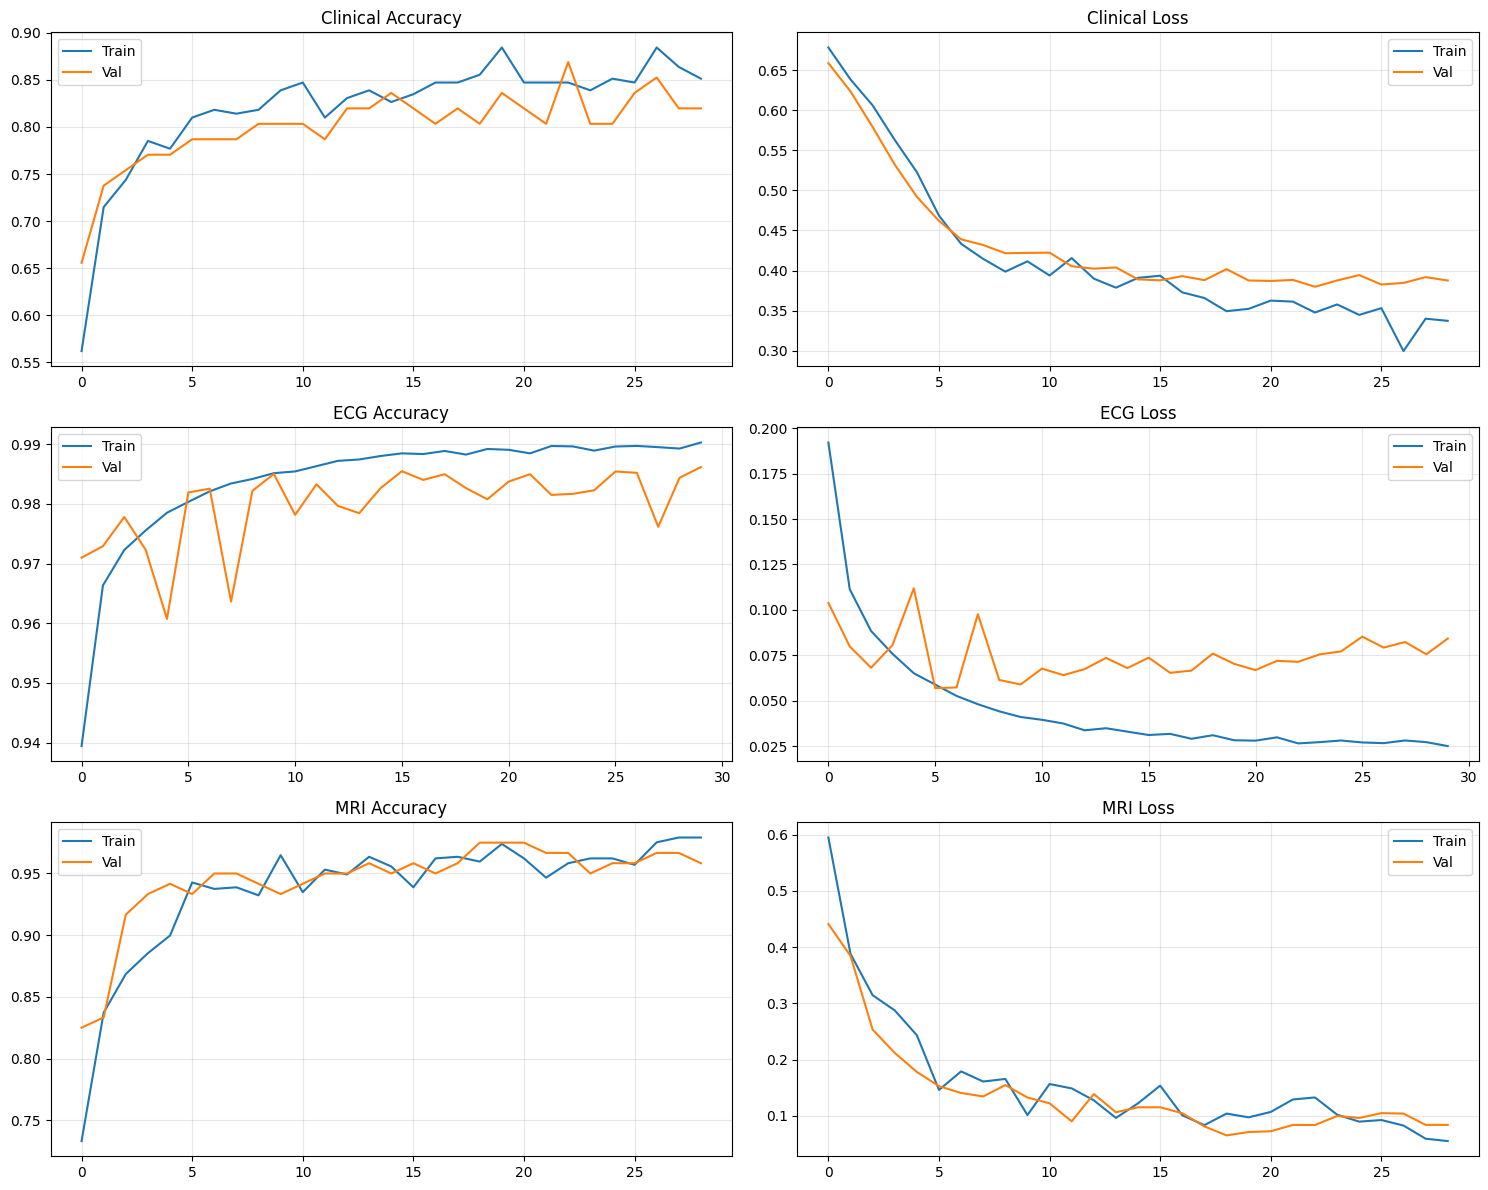

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for i, (name, hist) in enumerate([('Clinical', history_clinical), ('ECG', history_ecg), ('MRI', history_mri)]):
    axes[i,0].plot(hist.history['accuracy'],     label='Train')
    axes[i,0].plot(hist.history['val_accuracy'], label='Val')
    axes[i,0].set_title(f'{name} Accuracy'); axes[i,0].legend(); axes[i,0].grid(True, alpha=0.3)
    axes[i,1].plot(hist.history['loss'],     label='Train')
    axes[i,1].plot(hist.history['val_loss'], label='Val')
    axes[i,1].set_title(f'{name} Loss'); axes[i,1].legend(); axes[i,1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../models/stage1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 8.5 Model Interpretability (XAI) — Clinical, ECG, and MRI modules
This section demonstrates the predictions of the Stage 1 trained models using XAI modules on demo patient data.



  0%|          | 0/1 [00:00<?, ?it/s]

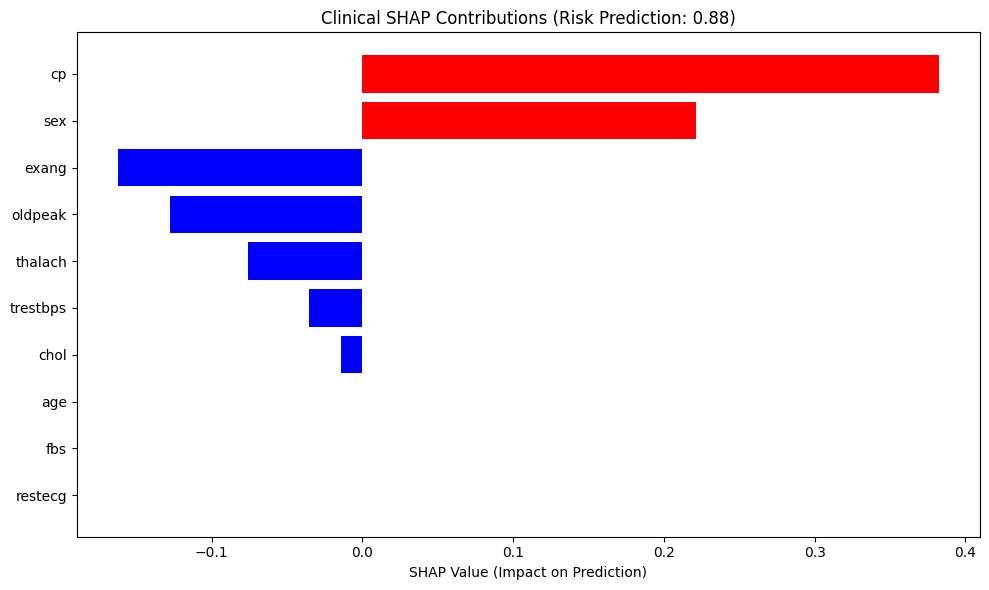

Interpretation: Patient at HIGH RISK primarily because: cp (+0.38) + sex (+0.22)


In [38]:
import sys
sys.path.append('..')
from shap_clinical import get_clinical_explanation, ClinicalShapExplainer
import matplotlib.pyplot as plt
from IPython.display import display, HTML

display(HTML("<h3>1. Clinical Model Explainability (SHAP)</h3>"))

# Using a demo patient
sample_patient = { 'age': 65.0, 'sex': 0.0, 'chol': 280.0, 'trestbps': 160.0, 'thalach': 120.0, 'cp': 3.0, 'exang': 1.0, 'oldpeak': 2.5 }

# Model paths are available from previous cells
res_clinical = get_clinical_explanation(sample_patient, str(CLINICAL_MODEL_PATH), '../models/clinical_scaler.pkl')

explainer = ClinicalShapExplainer(str(CLINICAL_MODEL_PATH), '../models/clinical_scaler.pkl')
bar_data = explainer.get_bar_plot_data(res_clinical)

plt.figure(figsize=(10, 6))
features = bar_data['features'][::-1]
contributions = bar_data['contributions'][::-1]
colors = ['red' if c > 0 else 'blue' for c in contributions]
plt.barh(features, contributions, color=colors)
plt.title(f'Clinical SHAP Contributions (Risk Prediction: {res_clinical["prediction"]:.2f})')
plt.xlabel('SHAP Value (Impact on Prediction)')
plt.tight_layout()
plt.show()

print("Interpretation:", res_clinical['interpretation'])


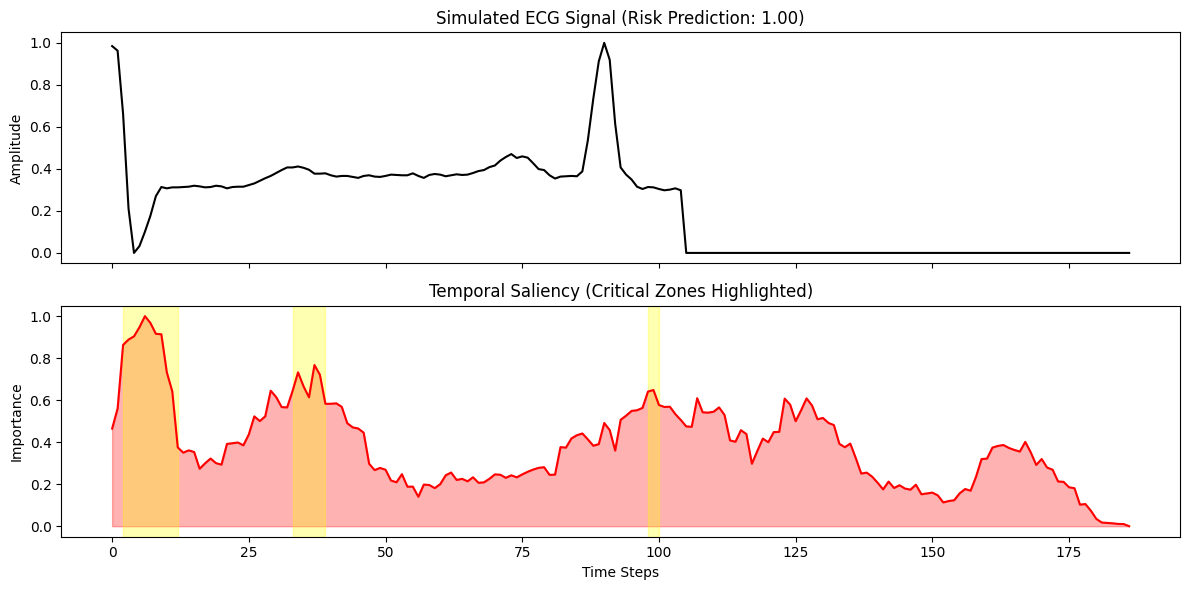

Critical Window: 8-48ms
Region 1: High model reliance on Sharp spike (potential artifact or isolated complex). Potential indicator of premature complex or signal noise.
Region 2: High model reliance on Sharp spike (potential artifact or isolated complex). Potential indicator of premature complex or signal noise.
Region 3: High model reliance on Sharp spike (potential artifact or isolated complex). Potential indicator of premature complex or signal noise.


In [27]:
import numpy as np
from saliency_ecg import explain_ecg
import matplotlib.pyplot as plt
from IPython.display import display, HTML

display(HTML("<h3>2. ECG Temporal Saliency Mapping</h3>"))

# Load a demo ECG sample
try:
    dummy_ecg = np.loadtxt('../demo_samples/demo_files/ecg_arrhythmia.csv', delimiter=',')
except OSError:
    print("Demo files not found. Ensure 'generate_demo_files.py' has been run.")
    dummy_ecg = np.random.randn(187)
    
if len(dummy_ecg) > 187:
    dummy_ecg = dummy_ecg[:187]
elif len(dummy_ecg) < 187:
    dummy_ecg = np.pad(dummy_ecg, (0, 187 - len(dummy_ecg)), 'constant')

res_ecg = explain_ecg(dummy_ecg, str(ECG_MODEL_PATH))
signal = np.array(res_ecg["ecg_signal"])
saliency = np.array(res_ecg["saliency"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(signal, color='black')
ax1.set_title(f'Simulated ECG Signal (Risk Prediction: {res_ecg["prediction"]:.2f})')
ax1.set_ylabel('Amplitude')

ax2.plot(saliency, color='red')
ax2.fill_between(range(len(saliency)), saliency, color='red', alpha=0.3)

for reg in res_ecg['peak_regions']:
    ax2.axvspan(reg['start'], reg['end'], color='yellow', alpha=0.3)
    
ax2.set_title('Temporal Saliency (Critical Zones Highlighted)')
ax2.set_xlabel('Time Steps')
ax2.set_ylabel('Importance')
plt.tight_layout()
plt.show()

print("Critical Window:", res_ecg['critical_window'])
for i, peak in enumerate(res_ecg['peak_regions']):
    print(f"Region {i+1}: {peak['interpretation']}")


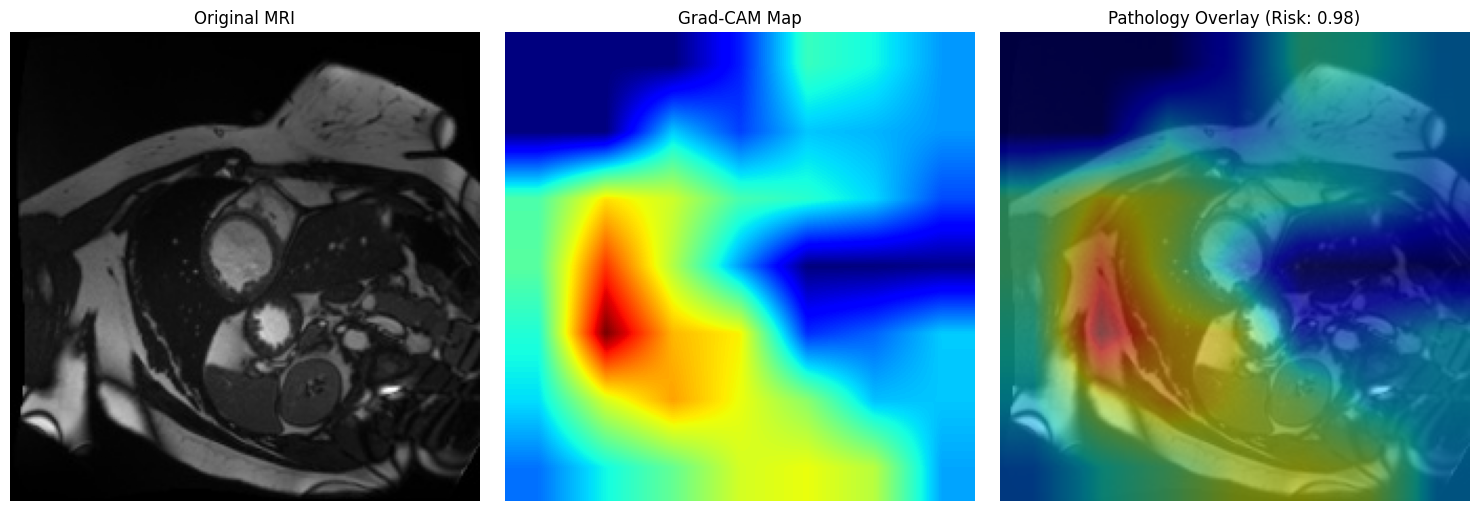

Confidence: 0.9807834625244141
- LAD clear
- LCx clear
- RCA shows abnormality


In [28]:
import tensorflow as tf
import matplotlib.cm as cm
from gradcam_mri import process_mri_for_explanation
from IPython.display import display, HTML

display(HTML("<h3>3. MRI Pathology Localization (Grad-CAM)</h3>"))

# Load a demo MRI image
try:
    img_raw = plt.imread('../demo_samples/demo_files/mri_patient101_disease.jpg')
    if len(img_raw.shape) == 2:
        img_raw = np.stack((img_raw,)*3, axis=-1)
    elif img_raw.shape[-1] == 4:
        img_raw = img_raw[..., :3]
except OSError:
    print("Demo files not found. Using random initialized input.")
    img_raw = np.random.rand(224, 224, 3) * 255.0

dummy_mri = tf.image.resize(img_raw, (224, 224)).numpy()
res_mri = process_mri_for_explanation(dummy_mri, str(MRI_MODEL_PATH))

heatmap = np.array(res_mri["heatmap"])
display_mri = dummy_mri
if display_mri.max() > 1.0:
    display_mri = display_mri / 255.0

jet = plt.colormaps["jet"] if hasattr(plt, "colormaps") else cm.get_cmap("jet")
jet_heatmap = jet(heatmap)[..., :3]
overlay_rgb = 0.5 * display_mri + 0.5 * jet_heatmap

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(display_mri)
axes[0].set_title('Original MRI')
axes[1].imshow(heatmap, cmap='jet')
axes[1].set_title('Grad-CAM Map')
axes[2].imshow(overlay_rgb)
axes[2].set_title(f'Pathology Overlay (Risk: {res_mri["prediction"]:.2f})')

for ax in axes:
    ax.axis('off')
    
plt.tight_layout()
plt.show()

print("Confidence:", res_mri['confidence'])
for region in res_mri['critical_regions']:
    print("-", region)


## 9. Stage 2 — Load & Freeze Branches

In [29]:
clinical_model_stage2 = keras.models.load_model(str(CLINICAL_MODEL_PATH))
ecg_model_stage2      = keras.models.load_model(str(ECG_MODEL_PATH))
mri_model_stage2      = keras.models.load_model(str(MRI_MODEL_PATH))

for model in [clinical_model_stage2, ecg_model_stage2, mri_model_stage2]:
    for layer in model.layers:
        layer.trainable = False

clinical_embedding_model = Model(
    inputs=clinical_model_stage2.input,
    outputs=clinical_model_stage2.get_layer('clinical_embedding').output
)
ecg_embedding_model = Model(
    inputs=ecg_model_stage2.input,
    outputs=ecg_model_stage2.get_layer('ecg_embedding').output
)
mri_embedding_model = Model(
    inputs=mri_model_stage2.input,
    outputs=mri_model_stage2.get_layer('mri_embedding').output
)
for m in [clinical_embedding_model, ecg_embedding_model, mri_embedding_model]:
    m.trainable = False

print("All branch weights frozen. Embedding models ready.")


All branch weights frozen. Embedding models ready.


## 10. Stage 2 — Extract Embeddings & Random Pairing

In [30]:
clinical_train_emb = clinical_embedding_model.predict(X_clinical_train, verbose=0)
clinical_test_emb  = clinical_embedding_model.predict(X_clinical_test,  verbose=0)
ecg_train_emb      = ecg_embedding_model.predict(X_ecg_train, verbose=0)
ecg_test_emb       = ecg_embedding_model.predict(X_ecg_test,  verbose=0)
mri_train_emb      = mri_embedding_model.predict(X_mri_train, verbose=0)
mri_test_emb       = mri_embedding_model.predict(X_mri_test,  verbose=0)

print(f"Embeddings — clinical: {clinical_train_emb.shape[1]}  ecg: {ecg_train_emb.shape[1]}  mri: {mri_train_emb.shape[1]}")

def create_fused_data(c_emb, e_emb, m_emb, 
                      c_labels, e_labels, m_labels, repeat=3):
    n = len(c_emb)
    X_out, y_out = [], []
    for _ in range(n * repeat):
        ci = np.random.randint(0, len(c_emb))
        ei = np.random.randint(0, len(e_emb))
        mi = np.random.randint(0, len(m_emb))

        votes = int(c_labels[ci]) + int(e_labels[ei]) + int(m_labels[mi])
        label = 1 if votes >= 2 else 0

        X_out.append(np.concatenate([c_emb[ci], e_emb[ei], m_emb[mi]]))
        y_out.append(label)

    return np.array(X_out, dtype=np.float32), np.array(y_out, dtype=np.float32)

X_fused_train, y_fused_train = create_fused_data(
    clinical_train_emb, ecg_train_emb, mri_train_emb,
    y_clinical_train, y_ecg_train_binary, y_mri_train,  
    repeat=3
)
X_fused_test, y_fused_test = create_fused_data(
    clinical_test_emb, ecg_test_emb, mri_test_emb,
    y_clinical_test, y_ecg_test_binary, y_mri_test,    
    repeat=1
)
print(f"Fused train: {X_fused_train.shape}  test: {X_fused_test.shape}")


Embeddings — clinical: 32  ecg: 64  mri: 64
Fused train: (726, 160)  test: (61, 160)


## 11. Stage 2 — Fusion Head Training

In [31]:


fusion_model = keras.Sequential([
    layers.Input(shape=(CONFIG['clinical_embedding_dim'] +
                        CONFIG['ecg_embedding_dim'] +
                        CONFIG['mri_embedding_dim'],)),
    layers.Dense(128, activation='relu', name='fusion_dense_1'),
    layers.Dropout(0.4, name='fusion_dropout'),
    layers.Dense(1, activation='sigmoid', name='fusion_output')
])

fusion_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall(), keras.metrics.AUC(name='auc')]
)

history_fusion = fusion_model.fit(
    X_fused_train, y_fused_train,
    validation_data=(X_fused_test, y_fused_test),
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    verbose=1
)

y_fusion_pred_prob = fusion_model.predict(X_fused_test, verbose=0)
y_fusion_pred = (y_fusion_pred_prob > 0.5).astype(int).flatten()
print("\nFusion Model Results:")
print(f"  Accuracy:  {accuracy_score(y_fused_test, y_fusion_pred):.4f}")
print(f"  Precision: {precision_score(y_fused_test, y_fusion_pred):.4f}")
print(f"  Recall:    {recall_score(y_fused_test, y_fusion_pred):.4f}")
print(f"  F1:        {f1_score(y_fused_test, y_fusion_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_fused_test, y_fusion_pred_prob):.4f}")


Epoch 1/30


23/23 [==============================] - 2s 48ms/step - loss: 1.3213 - accuracy: 0.6983 - precision_6: 0.5781 - recall_6: 0.5714 - auc: 0.7008 - val_loss: 0.6109 - val_accuracy: 0.7541 - val_precision_6: 0.7179 - val_recall_6: 0.8750 - val_auc: 0.8330
Epoch 2/30
23/23 [==============================] - 0s 4ms/step - loss: 0.7938 - accuracy: 0.7672 - precision_6: 0.6875 - recall_6: 0.6371 - auc: 0.8287 - val_loss: 0.5726 - val_accuracy: 0.7377 - val_precision_6: 0.8077 - val_recall_6: 0.6562 - val_auc: 0.8400
Epoch 3/30
23/23 [==============================] - 0s 3ms/step - loss: 0.6832 - accuracy: 0.7934 - precision_6: 0.7088 - recall_6: 0.7143 - auc: 0.8610 - val_loss: 0.4591 - val_accuracy: 0.7705 - val_precision_6: 0.7250 - val_recall_6: 0.9062 - val_auc: 0.8966
Epoch 4/30
23/23 [==============================] - 0s 3ms/step - loss: 0.4991 - accuracy: 0.8347 - precision_6: 0.7725 - recall_6: 0.7606 - auc: 0.9035 - val_loss: 0.4701 - val_accuracy: 0.8033 - val_precision_6: 0.8846 - v

## 12. Save Fusion Model

In [32]:
fusion_model.save(str(FUSION_MODEL_PATH))
print(f"Fusion model saved: {FUSION_MODEL_PATH}")
print("\nAll models saved:")
for p in [CLINICAL_MODEL_PATH, ECG_MODEL_PATH, MRI_MODEL_PATH, FUSION_MODEL_PATH]:
    print(f"  {p.name}")


Fusion model saved: ..\models\fusion_model.h5

All models saved:
  clinical_model.h5
  ecg_model.h5
  mri_model.h5
  fusion_model.h5


## 13. Evaluation — All Branches

In [33]:
results = []

y_cp = (clinical_model_stage2.predict(X_clinical_test, verbose=0) > 0.5).astype(int).flatten()
results.append({'Branch':'Clinical',
    'Accuracy':  accuracy_score(y_clinical_test, y_cp),
    'Precision': precision_score(y_clinical_test, y_cp, zero_division=0),
    'Recall':    recall_score(y_clinical_test, y_cp, zero_division=0),
    'F1':        f1_score(y_clinical_test, y_cp, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_clinical_test, clinical_model_stage2.predict(X_clinical_test, verbose=0))})

y_ep = (ecg_model_stage2.predict(X_ecg_test, verbose=0) > 0.5).astype(int).flatten()
results.append({'Branch':'ECG',
    'Accuracy':  accuracy_score(y_ecg_test_binary, y_ep),
    'Precision': precision_score(y_ecg_test_binary, y_ep, zero_division=0),
    'Recall':    recall_score(y_ecg_test_binary, y_ep, zero_division=0),
    'F1':        f1_score(y_ecg_test_binary, y_ep, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_ecg_test_binary, ecg_model_stage2.predict(X_ecg_test, verbose=0))})

y_mp = (mri_model_stage2.predict(X_mri_test, verbose=0) > 0.5).astype(int).flatten()
results.append({'Branch':'MRI',
    'Accuracy':  accuracy_score(y_mri_test, y_mp),
    'Precision': precision_score(y_mri_test, y_mp, zero_division=0),
    'Recall':    recall_score(y_mri_test, y_mp, zero_division=0),
    'F1':        f1_score(y_mri_test, y_mp, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_mri_test, mri_model_stage2.predict(X_mri_test, verbose=0))})

results.append({'Branch':'Fusion',
    'Accuracy':  accuracy_score(y_fused_test, y_fusion_pred),
    'Precision': precision_score(y_fused_test, y_fusion_pred, zero_division=0),
    'Recall':    recall_score(y_fused_test, y_fusion_pred, zero_division=0),
    'F1':        f1_score(y_fused_test, y_fusion_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_fused_test, y_fusion_pred_prob)})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


  Branch  Accuracy  Precision   Recall       F1  ROC-AUC
Clinical  0.803279   0.769231 0.909091 0.833333 0.912338
     ECG  0.986159   0.963418 0.956015 0.959702 0.993673
     MRI  0.975000   0.979381 0.989583 0.984456 0.995660
  Fusion  0.819672   0.888889 0.750000 0.813559 0.928879


## 14. Confusion Matrices

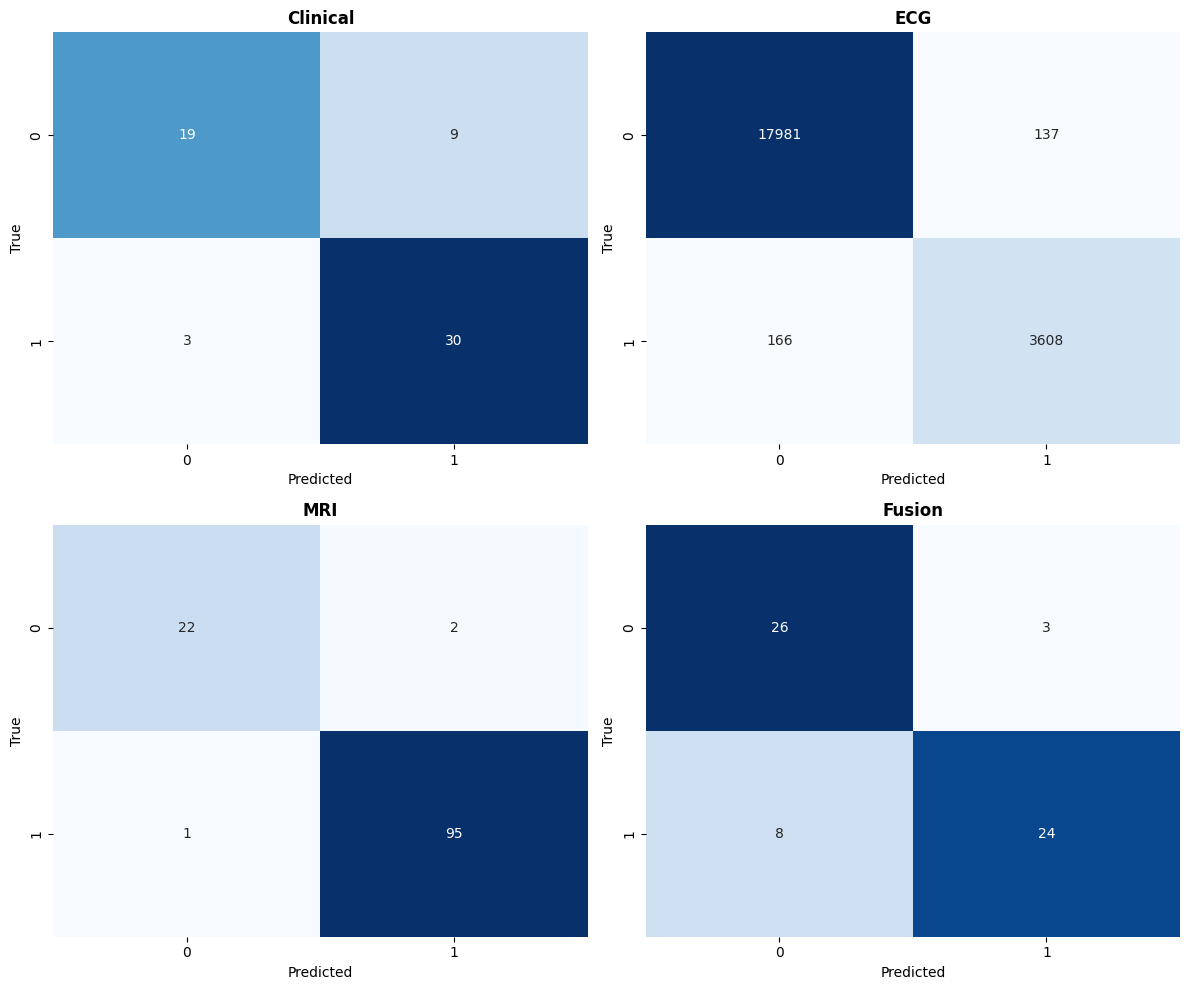

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, (yt, yp, title) in enumerate([
    (y_clinical_test,  y_cp,          'Clinical'),
    (y_ecg_test_binary,y_ep,          'ECG'),
    (y_mri_test,       y_mp,          'MRI'),
    (y_fused_test,     y_fusion_pred, 'Fusion')
]):
    ax = axes[i//2, i%2]
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig('../models/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


## 15. ROC Curves

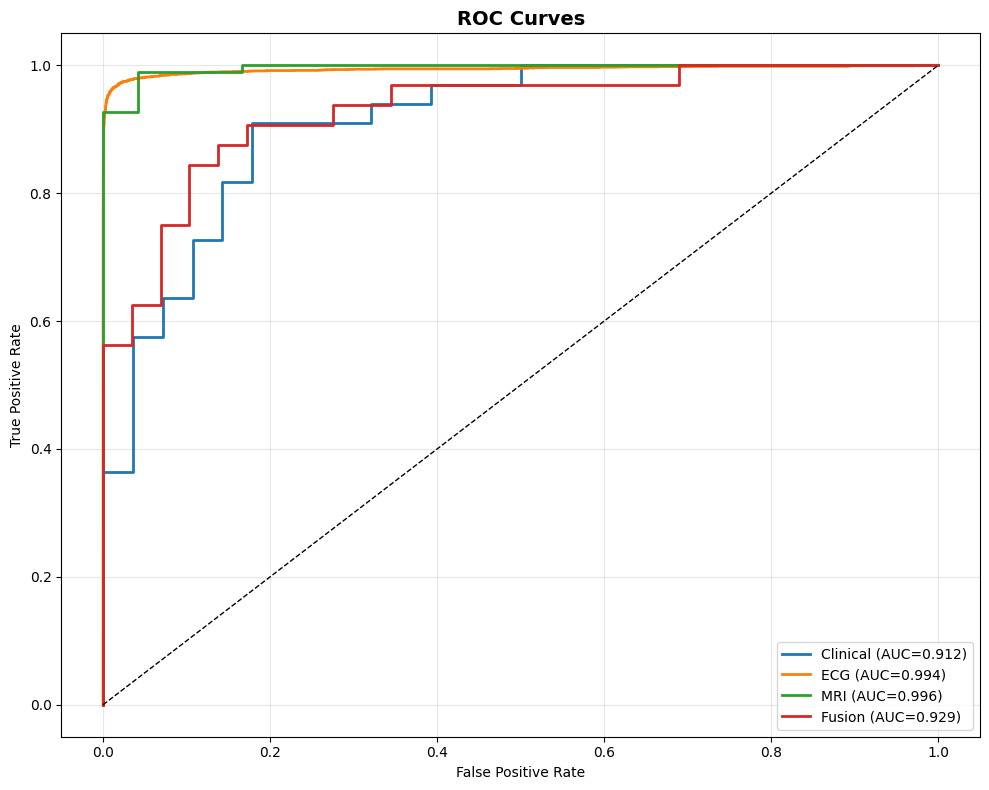

In [35]:
fig, ax = plt.subplots(figsize=(10, 8))
for probs, labels, name in [
    (clinical_model_stage2.predict(X_clinical_test, verbose=0).flatten(), y_clinical_test,   'Clinical'),
    (ecg_model_stage2.predict(X_ecg_test, verbose=0).flatten(),           y_ecg_test_binary, 'ECG'),
    (mri_model_stage2.predict(X_mri_test, verbose=0).flatten(),           y_mri_test,        'MRI'),
    (y_fusion_pred_prob.flatten(),                                         y_fused_test,      'Fusion'),
]:
    fpr, tpr, _ = roc_curve(labels, probs)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc_score(labels, probs):.3f})')
ax.plot([0,1],[0,1],'k--', linewidth=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves', fontsize=14, fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../models/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 16. Fusion Training Curves

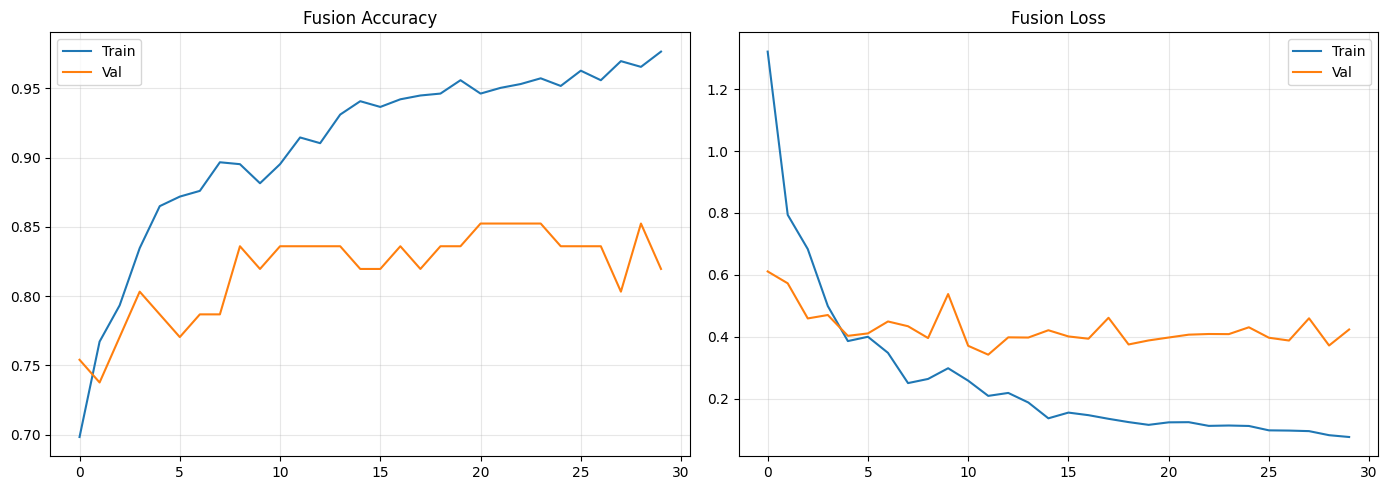

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_fusion.history['accuracy'],     label='Train')
axes[0].plot(history_fusion.history['val_accuracy'], label='Val')
axes[0].set_title('Fusion Accuracy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history_fusion.history['loss'],     label='Train')
axes[1].plot(history_fusion.history['val_loss'], label='Val')
axes[1].set_title('Fusion Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../models/fusion_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 17. Metrics Comparison

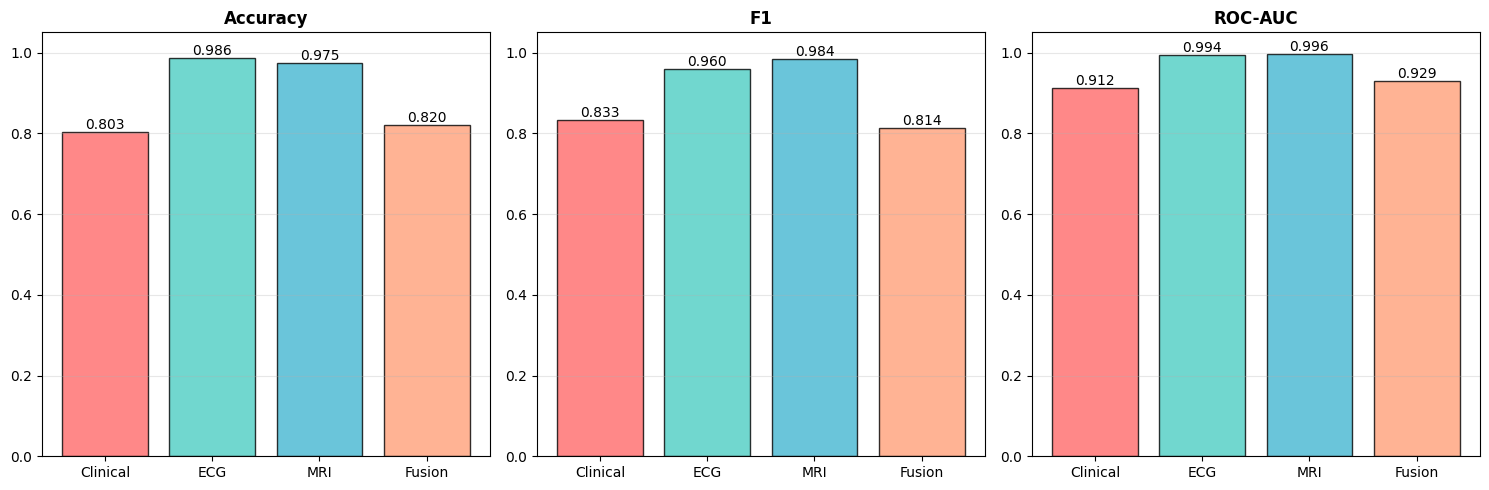

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']
for i, metric in enumerate(['Accuracy', 'F1', 'ROC-AUC']):
    vals = results_df[metric].values
    bars = axes[i].bar(results_df['Branch'].values, vals, color=colors, alpha=0.8, edgecolor='black')
    axes[i].set_ylim([0, 1.05]); axes[i].set_title(metric, fontweight='bold')
    axes[i].grid(axis='y', alpha=0.3)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2., h, f'{h:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.savefig('../models/metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 18. Inference Example

In [25]:
sample_indices = np.random.choice(len(X_clinical_test), 3, replace=False)
for i, si in enumerate(sample_indices):
    c_s = X_clinical_test[si:si+1]
    e_s = X_ecg_test[si % len(X_ecg_test):si % len(X_ecg_test)+1]
    m_s = X_mri_test[si % len(X_mri_test):si % len(X_mri_test)+1]

    c_prob = clinical_model_stage2.predict(c_s, verbose=0)[0][0]
    e_prob = ecg_model_stage2.predict(e_s, verbose=0)[0][0]
    m_prob = mri_model_stage2.predict(m_s, verbose=0)[0][0]

    fused_emb = np.concatenate([
        clinical_embedding_model.predict(c_s, verbose=0),
        ecg_embedding_model.predict(e_s, verbose=0),
        mri_embedding_model.predict(m_s, verbose=0)
    ], axis=1)
    f_prob = fusion_model.predict(fused_emb, verbose=0)[0][0]

    print(f"Sample {i+1}  True: {'Disease' if y_clinical_test[si]==1 else 'Healthy'}")
    print(f"  Clinical: {c_prob:.4f}  ECG: {e_prob:.4f}  MRI: {m_prob:.4f}  Fusion: {f_prob:.4f}  Confidence: {max(f_prob, 1-f_prob)*100:.1f}%")


Sample 1  True: Disease
  Clinical: 0.6795  ECG: 0.0000  MRI: 0.9853  Fusion: 0.9648  Confidence: 96.5%
Sample 2  True: Disease
  Clinical: 0.9324  ECG: 0.0000  MRI: 0.9999  Fusion: 0.9971  Confidence: 99.7%
Sample 3  True: Disease
  Clinical: 0.7862  ECG: 0.0000  MRI: 0.0006  Fusion: 0.0000  Confidence: 100.0%
